IRIS DATASET
   sepal length (cm)  sepal width (cm)  petal length (cm)  petal width (cm)  \
0                5.1               3.5                1.4               0.2   
1                4.9               3.0                1.4               0.2   
2                4.7               3.2                1.3               0.2   
3                4.6               3.1                1.5               0.2   
4                5.0               3.6                1.4               0.2   

  Species  
0  setosa  
1  setosa  
2  setosa  
3  setosa  
4  setosa  

Dataset Shape: (150, 5)

Perceptron Model Training Completed!

Predicted Values:
[0 2 1 1 0 2 0 0 2 1 2 2 2 2 0 0 0 1 1 2 0 2 1 1 2 2 1 0 2 0]

Actual Values:
[0 2 1 1 0 1 0 0 2 1 2 2 2 1 0 0 0 1 1 2 0 2 1 2 2 1 1 0 2 0]

Model Accuracy: 86.67%

CLASSIFICATION REPORT
              precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        10
  versicolor       0.88      0.70      0.78        10
   virgi

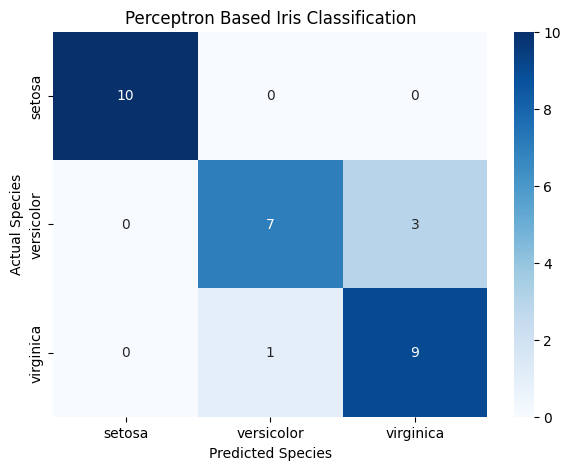


NEW FLOWER DETAILS
Sepal Length: 5.1
Sepal Width: 3.5
Petal Length: 1.4
Petal Width: 0.2

Predicted Flower Species: setosa


In [8]:

# PERCEPTRON BASED IRIS FLOWER CLASSIFICATION

# Step 1: Import required libraries
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import Perceptron
from sklearn.metrics import accuracy_score
from sklearn.metrics import confusion_matrix
from sklearn.metrics import classification_report

# Step 2: Load Iris dataset
iris = load_iris()

X = iris.data
y = iris.target

# Step 3: Display dataset
df = pd.DataFrame(
    X,
    columns=iris.feature_names
)

df['Species'] = iris.target_names[y]

print("IRIS DATASET")
print(df.head())

print("\nDataset Shape:", df.shape)

# Step 4: Split dataset into training and testing data
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

# Step 5: Feature scaling
scaler = StandardScaler()

X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

# Step 6: Create Perceptron classifier
model = Perceptron(
    max_iter=1000,
    eta0=0.1,
    random_state=42
)

# Step 7: Train the model
model.fit(X_train, y_train)

print("\nPerceptron Model Training Completed!")

# Step 8: Predict test data
y_pred = model.predict(X_test)

print("\nPredicted Values:")
print(y_pred)

print("\nActual Values:")
print(y_test)

# Step 9: Calculate accuracy
accuracy = accuracy_score(y_test, y_pred)

print("\nModel Accuracy: {:.2f}%".format(
    accuracy * 100
))

# Step 10: Display classification report
print("\nCLASSIFICATION REPORT")

print(classification_report(
    y_test,
    y_pred,
    target_names=iris.target_names
))

# Step 11: Generate confusion matrix
cm = confusion_matrix(y_test, y_pred)

print("\nCONFUSION MATRIX")
print(cm)

# Step 12: Visualize confusion matrix
plt.figure(figsize=(7, 5))

sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=iris.target_names,
    yticklabels=iris.target_names
)

plt.xlabel("Predicted Species")
plt.ylabel("Actual Species")
plt.title("Perceptron Based Iris Classification")

plt.show()

# Step 13: Predict a new flower
new_flower = [[5.1, 3.5, 1.4, 0.2]]

new_flower_scaled = scaler.transform(new_flower)

prediction = model.predict(new_flower_scaled)

print("\nNEW FLOWER DETAILS")
print("Sepal Length: 5.1")
print("Sepal Width: 3.5")
print("Petal Length: 1.4")
print("Petal Width: 0.2")

print("\nPredicted Flower Species:",
      iris.target_names[prediction[0]])
